# ML from Scratch - 2 - Logistic Regression

## Importing

In [1]:
import importlib
import my_logistic_regression

importlib.reload(my_logistic_regression)
from my_logistic_regression import Logistic_Regression

## Synthetic Data

In [2]:
import numpy as np

np.random.seed(42)

X = np.random.randn(100, 5)

weights = np.random.randn(X.shape[1])

proba = X @ weights.T + 0.5 + np.random.randn(X.shape[0])

sigmoid = 1 / (1 + (np.exp(-proba)))

y = np.where(sigmoid >= 0.5, 1, 0)

y

array([1, 1, 0, 0, 1, 0, 1, 1, 1, 0, 1, 1, 0, 1, 1, 1, 0, 1, 1, 0, 0, 1,
       1, 1, 0, 1, 0, 1, 1, 1, 1, 1, 0, 1, 0, 0, 1, 1, 1, 0, 1, 0, 1, 1,
       0, 1, 0, 0, 1, 1, 0, 1, 1, 1, 0, 1, 0, 0, 1, 1, 0, 1, 0, 1, 1, 1,
       0, 1, 0, 1, 1, 1, 1, 0, 0, 1, 1, 1, 1, 0, 0, 0, 1, 1, 1, 1, 0, 1,
       1, 1, 1, 1, 1, 1, 0, 1, 1, 1, 1, 1])

In [3]:
model = Logistic_Regression()

model.fit(X, y)

In [4]:
from sklearn.metrics import accuracy_score

y_pred = model.predict(X)

accuracy_score(y, y_pred)

0.96

## Titanic

In [5]:
import pandas as pd

train_df = pd.read_csv('../data/titanic/train.csv').set_index('PassengerId')

train_df.head()

,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
PassengerId,,,,,,,,,,,
1,0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,NaN,S
2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C85,C
3,1,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,NaN,S
4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,113803,53.1000,C123,S
5,0,3,"Allen, Mr. William Henry",male,35.0,0,0,373450,8.0500,NaN,S


### EDA

In [6]:
train_df.isnull().sum()

Survived      0
Pclass        0
Name          0
Sex           0
Age         177
SibSp         0
Parch         0
Ticket        0
Fare          0
Cabin       687
Embarked      2
dtype: int64

In [7]:
train_df.describe()

,Survived,Pclass,Age,SibSp,Parch,Fare
count,891.000000,891.000000,714.000000,891.000000,891.000000,891.000000
mean,0.383838,2.308642,29.699118,0.523008,0.381594,32.204208
std,0.486592,0.836071,14.526497,1.102743,0.806057,49.693429
min,0.000000,1.000000,0.420000,0.000000,0.000000,0.000000
25%,0.000000,2.000000,20.125000,0.000000,0.000000,7.910400
50%,0.000000,3.000000,28.000000,0.000000,0.000000,14.454200
75%,1.000000,3.000000,38.000000,1.000000,0.000000,31.000000
max,1.000000,3.000000,80.000000,8.000000,6.000000,512.329200


In [8]:
train_df.info()

<class 'pandas.core.frame.DataFrame'>
Index: 891 entries, 1 to 891
Data columns (total 11 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   Survived  891 non-null    int64  
 1   Pclass    891 non-null    int64  
 2   Name      891 non-null    object 
 3   Sex       891 non-null    object 
 4   Age       714 non-null    float64
 5   SibSp     891 non-null    int64  
 6   Parch     891 non-null    int64  
 7   Ticket    891 non-null    object 
 8   Fare      891 non-null    float64
 9   Cabin     204 non-null    object 
 10  Embarked  889 non-null    object 
dtypes: float64(2), int64(4), object(5)
memory usage: 83.5+ KB


In [9]:
train_df['Embarked'].unique()

array(['S', 'C', 'Q', nan], dtype=object)

In [10]:
train_df['Age'].sort_values().unique()

array([ 0.42,  0.67,  0.75,  0.83,  0.92,  1.  ,  2.  ,  3.  ,  4.  ,
        5.  ,  6.  ,  7.  ,  8.  ,  9.  , 10.  , 11.  , 12.  , 13.  ,
       14.  , 14.5 , 15.  , 16.  , 17.  , 18.  , 19.  , 20.  , 20.5 ,
       21.  , 22.  , 23.  , 23.5 , 24.  , 24.5 , 25.  , 26.  , 27.  ,
       28.  , 28.5 , 29.  , 30.  , 30.5 , 31.  , 32.  , 32.5 , 33.  ,
       34.  , 34.5 , 35.  , 36.  , 36.5 , 37.  , 38.  , 39.  , 40.  ,
       40.5 , 41.  , 42.  , 43.  , 44.  , 45.  , 45.5 , 46.  , 47.  ,
       48.  , 49.  , 50.  , 51.  , 52.  , 53.  , 54.  , 55.  , 55.5 ,
       56.  , 57.  , 58.  , 59.  , 60.  , 61.  , 62.  , 63.  , 64.  ,
       65.  , 66.  , 70.  , 70.5 , 71.  , 74.  , 80.  ,   nan])

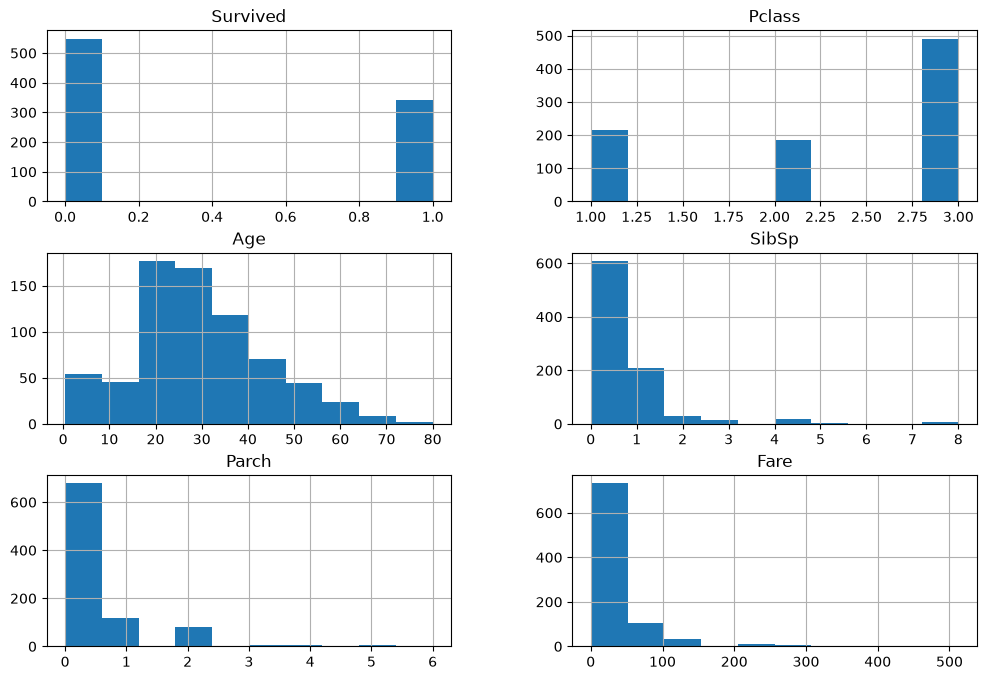

In [11]:
import matplotlib.pyplot as plt

train_df.hist(figsize=(12,8))

plt.show()

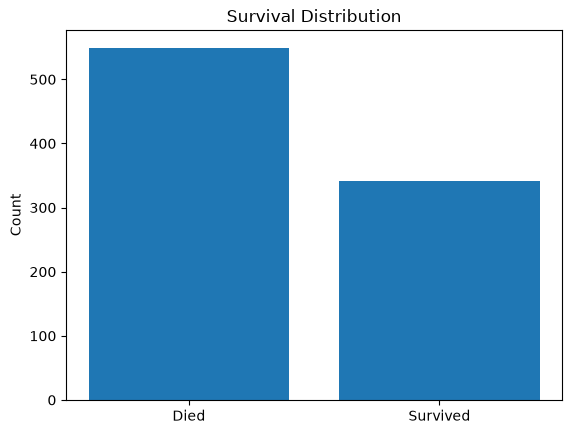

In [12]:
survived_counts = train_df["Survived"].value_counts().sort_index()

plt.bar(survived_counts.index, survived_counts.values)
plt.xticks([0, 1], ["Died", "Survived"])
plt.ylabel("Count")
plt.title("Survival Distribution")
plt.show()

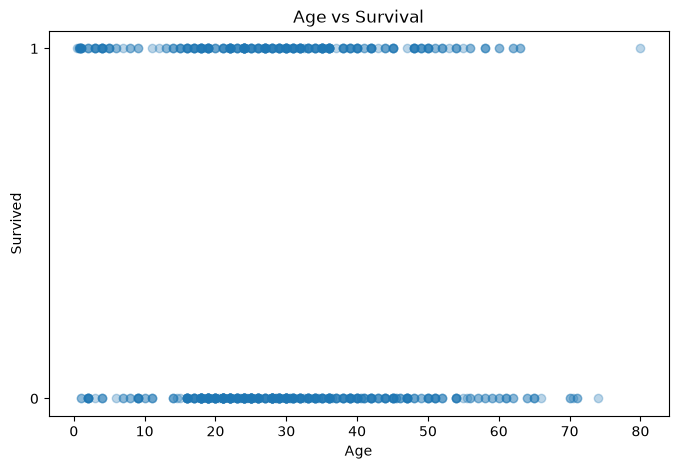

In [13]:
plt.figure(figsize=(8,5))

plt.scatter(
    train_df["Age"],
    train_df["Survived"],
    alpha=0.3
)

plt.yticks([0,1])
plt.xlabel("Age")
plt.ylabel("Survived")
plt.title("Age vs Survival")
plt.show()


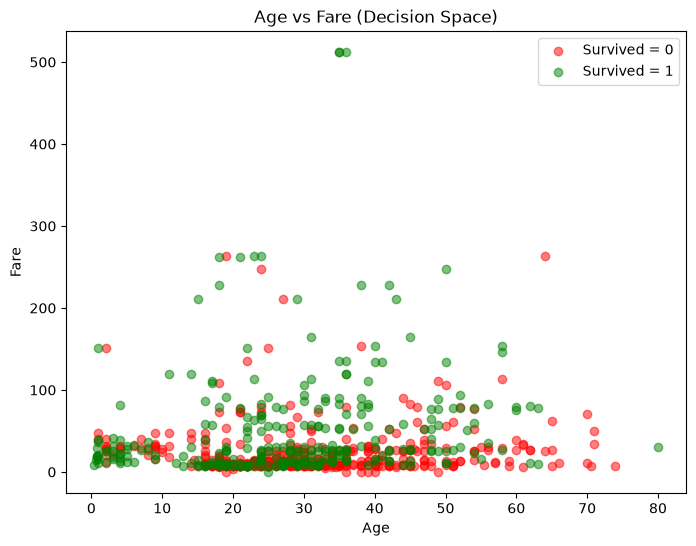

In [14]:
plt.figure(figsize=(8,6))

for label, color in zip([0,1], ["red", "green"]):
    subset = train_df[train_df["Survived"] == label]
    plt.scatter(
        subset["Age"],
        subset["Fare"],
        alpha=0.5,
        label=f"Survived = {label}",
        color=color
    )

plt.xlabel("Age")
plt.ylabel("Fare")
plt.legend()
plt.title("Age vs Fare (Decision Space)")
plt.show()


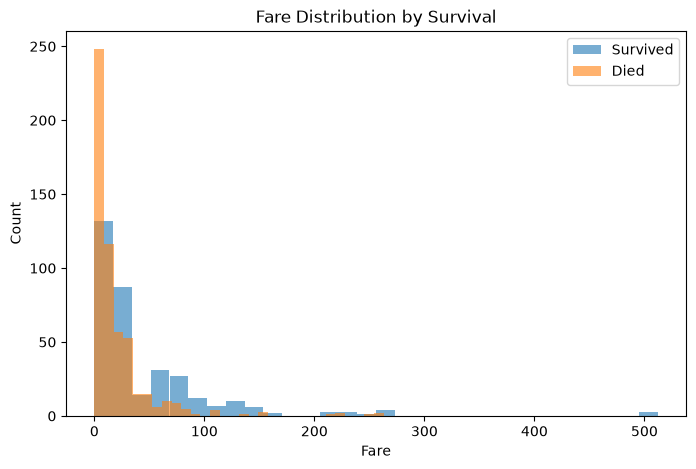

In [15]:
plt.figure(figsize=(8,5))

plt.hist(train_df[train_df["Survived"] == 1]["Fare"], bins=30, alpha=0.6, label="Survived")
plt.hist(train_df[train_df["Survived"] == 0]["Fare"], bins=30, alpha=0.6, label="Died")

plt.xlabel("Fare")
plt.ylabel("Count")
plt.legend()
plt.title("Fare Distribution by Survival")
plt.show()

### Preprocessing

In [16]:
from sklearn.base import BaseEstimator, TransformerMixin

class FamilyFeatures(BaseEstimator, TransformerMixin):
    def __init__(self):
        pass

    def fit(self, X, y=None):
        self.n_features_in_ = X.shape[1]
        return self

    def transform(self, X):
        X = X.copy()
        X['FamilySize'] = X['Parch'] + X['SibSp'] + 1
        X['IsAlone'] = (X['FamilySize'] == 1).astype(int)

        return X

In [17]:
from sklearn.pipeline import make_pipeline

feature_eng_pipeline = make_pipeline(
    FamilyFeatures(),
)

feature_eng_pipeline

,steps,"[('familyfeatures', ...)]"
,transform_input,None
,memory,None
,verbose,False


In [18]:
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler

num_pipeline = make_pipeline(
    SimpleImputer(strategy='median'),
    StandardScaler()
)

num_pipeline

,steps,"[('simpleimputer', ...), ('standardscaler', ...)]"
,transform_input,None
,memory,None
,verbose,False
,missing_values,nan
,strategy,'median'
,fill_value,None
,copy,True
,add_indicator,False
,keep_empty_features,False
,copy,True


In [19]:
from sklearn.preprocessing import OneHotEncoder

obj_pipeline = make_pipeline(
    SimpleImputer(strategy='most_frequent'),
    OneHotEncoder(handle_unknown='ignore')
)

obj_pipeline

,steps,"[('simpleimputer', ...), ('onehotencoder', ...)]"
,transform_input,None
,memory,None
,verbose,False
,missing_values,nan
,strategy,'most_frequent'
,fill_value,None
,copy,True
,add_indicator,False
,keep_empty_features,False
,categories,'auto'


In [20]:
from sklearn.preprocessing import OrdinalEncoder

gender_pipeline = make_pipeline(
    OrdinalEncoder()
)

gender_pipeline

,steps,"[('ordinalencoder', ...)]"
,transform_input,None
,memory,None
,verbose,False
,categories,'auto'
,dtype,<class 'numpy.float64'>
,handle_unknown,'error'
,unknown_value,None
,encoded_missing_value,nan
,min_frequency,None
,max_categories,None


In [21]:
from sklearn.compose import ColumnTransformer

preprocessor = ColumnTransformer([
        ('num', num_pipeline, ['Age', 'Fare', 'FamilySize', 'SibSp', 'Parch']),
        ('obj', obj_pipeline, ['Embarked']),
        ('gender', gender_pipeline, ['Sex']),
        ('pass', 'passthrough', ['Pclass', 'IsAlone'])
        ], remainder='drop')

preprocessor

,transformers,"[('num', ...), ('obj', ...), ...]"
,remainder,'drop'
,sparse_threshold,0.3
,n_jobs,None
,transformer_weights,None
,verbose,False
,verbose_feature_names_out,True
,force_int_remainder_cols,'deprecated'
,missing_values,nan
,strategy,'median'
,fill_value,None


In [22]:
target = 'Survived'

X = train_df.drop(columns=[target])
y = train_df[target]

In [23]:
from sklearn.model_selection import train_test_split

X_train, X_val, y_train, y_val = train_test_split(X, y, stratify=y, test_size=0.3, random_state=42)

X_train.shape, X_val.shape

((623, 10), (268, 10))

In [24]:
X_train_engineered = feature_eng_pipeline.fit_transform(X_train)
X_val_engineered = feature_eng_pipeline.transform(X_val)
X_full_engineered = feature_eng_pipeline.transform(X)

X_train_engineered.shape, X_val_engineered.shape, X_full_engineered.shape

((623, 12), (268, 12), (891, 12))

In [25]:
X_train_preprocessed = preprocessor.fit_transform(X_train_engineered)
X_val_preprocessed = preprocessor.transform(X_val_engineered)
X_full_preprocessed = preprocessor.transform(X_full_engineered)

X_train_preprocessed.shape, X_val_preprocessed.shape, X_full_preprocessed.shape

((623, 11), (268, 11), (891, 11))

In [26]:
X_train_preprocessed = pd.DataFrame(X_train_preprocessed, index=X_train_engineered.index, columns=preprocessor.get_feature_names_out())
X_val_preprocessed = pd.DataFrame(X_val_preprocessed, index=X_val_engineered.index, columns=preprocessor.get_feature_names_out())
X_full_preprocessed = pd.DataFrame(X_full_preprocessed, index=X_full_engineered.index, columns=preprocessor.get_feature_names_out())

X_train_preprocessed.head()

,num__Age,num__Fare,num__FamilySize,num__SibSp,num__Parch,obj__Embarked_C,obj__Embarked_Q,obj__Embarked_S,gender__Sex,pass__Pclass,pass__IsAlone
PassengerId,,,,,,,,,,,
749,-0.831890,0.465738,0.110685,0.562957,-0.448665,0.0,0.0,1.0,1.0,1.0,0.0
46,-0.064873,-0.478269,-0.558800,-0.474682,-0.448665,0.0,0.0,1.0,1.0,3.0,1.0
29,-0.064873,-0.481848,-0.558800,-0.474682,-0.448665,0.0,1.0,0.0,0.0,3.0,1.0
634,-0.064873,-0.646954,-0.558800,-0.474682,-0.448665,0.0,0.0,1.0,1.0,1.0,1.0
404,-0.141574,-0.314823,0.110685,0.562957,-0.448665,0.0,0.0,1.0,1.0,3.0,0.0


### Modelling

#### My model

In [27]:
model.fit(X_train_preprocessed, y_train)

In [28]:
y_pred = model.predict(X_val_preprocessed)

accuracy_score(y_val, y_pred)

0.8022388059701493

#### SciKit-Learn

In [29]:
from sklearn.linear_model import LogisticRegression

model_sklearn = LogisticRegression(random_state=42)

model_sklearn.fit(X_train_preprocessed, y_train)

,penalty,'l2'
,dual,False
,tol,0.0001
,C,1.0
,fit_intercept,True
,intercept_scaling,1
,class_weight,None
,random_state,42
,solver,'lbfgs'
,max_iter,100
,multi_class,'deprecated'


In [30]:
y_pred_sklearn = model_sklearn.predict(X_val_preprocessed)

accuracy_score(y_val, y_pred_sklearn)

0.8022388059701493

### Retraining and Submission

In [31]:
model.fit(X_full_preprocessed, y)

In [32]:
model_sklearn.fit(X_full_preprocessed, y)

,penalty,'l2'
,dual,False
,tol,0.0001
,C,1.0
,fit_intercept,True
,intercept_scaling,1
,class_weight,None
,random_state,42
,solver,'lbfgs'
,max_iter,100
,multi_class,'deprecated'


In [33]:
test_df = pd.read_csv('../data/titanic/test.csv').set_index('PassengerId')

test_df.head()

,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
PassengerId,,,,,,,,,,
892,3,"Kelly, Mr. James",male,34.5,0,0,330911,7.8292,NaN,Q
893,3,"Wilkes, Mrs. James (Ellen Needs)",female,47.0,1,0,363272,7.0000,NaN,S
894,2,"Myles, Mr. Thomas Francis",male,62.0,0,0,240276,9.6875,NaN,Q
895,3,"Wirz, Mr. Albert",male,27.0,0,0,315154,8.6625,NaN,S
896,3,"Hirvonen, Mrs. Alexander (Helga E Lindqvist)",female,22.0,1,1,3101298,12.2875,NaN,S


In [34]:
X_test_engineered = feature_eng_pipeline.transform(test_df)
X_test_preprocessed = preprocessor.transform(X_test_engineered)

X_test_preprocessed = pd.DataFrame(X_test_preprocessed, index=X_test_engineered.index, columns=preprocessor.get_feature_names_out())

X_test_preprocessed.head()

,num__Age,num__Fare,num__FamilySize,num__SibSp,num__Parch,obj__Embarked_C,obj__Embarked_Q,obj__Embarked_S,gender__Sex,pass__Pclass,pass__IsAlone
PassengerId,,,,,,,,,,,
892,0.356987,-0.482896,-0.558800,-0.474682,-0.448665,0.0,1.0,0.0,1.0,3.0,1.0
893,1.315758,-0.500272,0.110685,0.562957,-0.448665,0.0,0.0,1.0,0.0,3.0,0.0
894,2.466283,-0.443956,-0.558800,-0.474682,-0.448665,0.0,1.0,0.0,1.0,2.0,1.0
895,-0.218276,-0.465435,-0.558800,-0.474682,-0.448665,0.0,0.0,1.0,1.0,3.0,1.0
896,-0.601785,-0.389474,0.780171,0.562957,0.740774,0.0,0.0,1.0,0.0,3.0,0.0


In [35]:
y_test_pred = model.predict(X_test_preprocessed)
y_test_pred_sklearn = model_sklearn.predict(X_test_preprocessed)

In [36]:
submission_df = pd.DataFrame(y_test_pred, columns=['Survived'], index=test_df.index)

submission_df.to_csv('../data/titanic/submissions/submission_my_model.csv', sep=',')

In [37]:
submission_sklearn_df = pd.DataFrame(y_test_pred_sklearn, columns=['Survived'], index=test_df.index)

submission_sklearn_df.to_csv('../data/titanic/submissions/submission_sklearn.csv', sep=',')

Kaggle Score for my model: `0.76315`

Kaggle Score for SciKit-Learn model: `0.76315`